In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT => temperature
# V => vaccum
# AP => pressure
# RH => huminidity

# PE => produced energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
x = df.drop("PE", axis=1)
y = df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
# split out data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state=42
)

In [9]:
df.shape

(9568, 5)

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [11]:
x_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [12]:
import torch 
import torch.nn as nn

x_train_tensor = torch.tensor(x_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

x_test_tensor = torch.tensor(x_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)


In [13]:
type(x_train_scaled)

numpy.ndarray

In [14]:
type(y_train)
y_train.shape

(7654,)

In [15]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

In [16]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

### Deep Learning

In [17]:
# Define our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(x_train.shape[1], 6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output layer
            nn.Linear(6, 1)
        )

    def forward(self, x):
        return self.model(x)

In [18]:
import torch.optim as optim
model = ANN()

#loss, optimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())


In [19]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")
epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # training loss

    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()

        outputs = model(xb)
        loss = crietrion(outputs, yb)# compute loss
        loss.backward() #back prop...compute gradients
        optimizer.step() # param update

        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    #validation
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
       for xb, yb in test_loader:
           outputs = model(xb)
           loss = crietrion(outputs, yb)
           running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)
    
    print(f"epoch ${epoch+1}/{epochs} ==> train loss = $ {epoch_train_loss} & val loss  = ${epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")

epoch $1/100 ==> train loss = $ 205803.26529947916 & val loss  = $204206.140625
epoch $2/100 ==> train loss = $ 197276.66302083334 & val loss  = $185602.109375
epoch $3/100 ==> train loss = $ 165054.41588541667 & val loss  = $140641.65625
epoch $4/100 ==> train loss = $ 112506.49560546875 & val loss  = $85440.65625
epoch $5/100 ==> train loss = $ 63538.93553873698 & val loss  = $46367.62890625
epoch $6/100 ==> train loss = $ 35484.56244303386 & val loss  = $27882.494140625
epoch $7/100 ==> train loss = $ 22917.22751871745 & val loss  = $19401.49609375
epoch $8/100 ==> train loss = $ 16832.71075032552 & val loss  = $14808.0146484375
epoch $9/100 ==> train loss = $ 13053.074633789063 & val loss  = $11344.66796875
epoch $10/100 ==> train loss = $ 9768.30097249349 & val loss  = $8234.7275390625
epoch $11/100 ==> train loss = $ 6874.338046773275 & val loss  = $5618.47314453125
epoch $12/100 ==> train loss = $ 4596.1575927734375 & val loss  = $3703.37109375
epoch $13/100 ==> train loss = $ 2

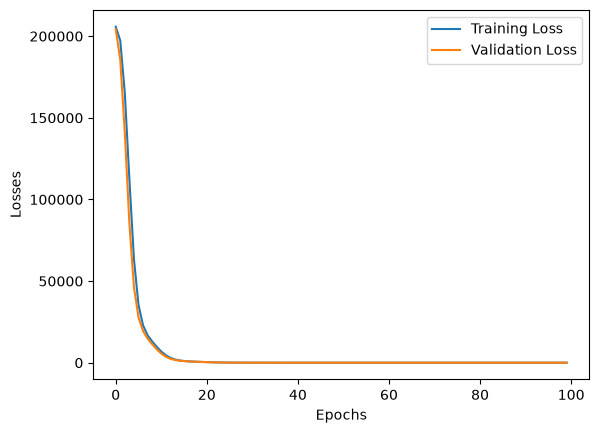

In [20]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [21]:
# Loading the best model
model. load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [22]:
# Evalute our model

model.eval()
with torch.no_grad():
    train_preds = model(x_train_tensor)
    test_preds = model(x_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss)
print("Testing MSE:", test_mse_loss)

Training MSE: tensor(20.8991)
Testing MSE: tensor(19.4621)


In [23]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9319850934547582


In [24]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,predicted Values,Actual Values
0,435.639160,433.27
1,436.222870,438.16
2,460.586456,458.42
3,476.274658,480.82
4,435.218140,441.41
...,...,...
1909,451.206940,456.70
1910,431.771088,438.04
1911,467.421234,467.80
1912,431.003387,437.14
